In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Convolutional Neural Networks (LeNet)

We now have every part of a convolutional network: the convolutional layer of
that section, padding and stride to control its output
(that section), channels to detect many patterns at once
(that section), and pooling to summarize neighborhoods
(that section). This section puts them together into a complete
classifier and asks whether it is better than the MLP we trained on the same
data.

The MLP of that section reached about 87% validation
accuracy on Fashion-MNIST after 30 epochs, using about 204,000 parameters. It
flattens each $28\times28$ image into a vector of 784 numbers before its first
layer. Shuffling the pixels in the same way in every image would therefore
not change what it can learn: the MLP does not know which pixels are
neighbors, and it must learn a pattern separately at every position where the
pattern can occur. Convolutional layers keep the spatial layout and use the
same kernel at every position, so they need far fewer parameters. We train
the convolutional classifier with the same loss, optimizer, and number of
epochs as the MLP and compare their validation accuracy.

The network we build is *LeNet*, after Yann LeCun, who developed it with his
colleagues at AT&T Bell Labs to recognize handwritten digits
[@LeCun.Bottou.Bengio.ea.1998]. It was the result of a decade of work
that began with an early convolutional network for images trained end to
end by backpropagation [@LeCun.Boser.Denker.ea.1989]. LeNet-5, the version of 1998, reached an
error rate below 1% on handwritten digits, on par with the support vector
machines of the time, and variants of it read the handwritten amounts on
bank checks in commercial systems. It showed that a network trained from
examples could replace a hand-engineered recognition pipeline.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

## The LeNet Architecture

LeNet consists of two parts, shown in the figure: a convolutional
encoder with two convolutional layers, and a dense block with three fully
connected layers.

![Data flow in LeNet on one $28\times28$ Fashion-MNIST image, with the feature maps drawn to scale. Each shaded window produces the dark unit it points to in the next layer. The three fully connected layers have 120, 84, and 10 outputs.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/lenet.svg)

Each convolutional block consists of a convolutional layer with a
$5\times5$ kernel, a sigmoid activation, and $2\times2$ average pooling with
stride 2. The first convolutional layer has 6 output channels and the second
has 16, so the number of channels grows while each pooling layer halves the
height and the width.

The encoder's output has shape (batch size, height, width, channels).

The dense block needs one vector per example, so we first flatten the
encoder's output into a matrix with one row per example. Its three fully
connected layers have 120, 84, and 10 outputs. The last layer has one output
per class, as in softmax regression.

This is the common teaching version of LeNet-5, not an exact reproduction.
The network of 1998 had the same alternating convolutions and pooling and
the same 6, 16, 120, and 84 channels and hidden units, but it used a scaled
tanh as activation, pooling with a trainable weight and bias, partial
connections between the two convolutional layers, and radial-basis output
units. Its 120-unit layer was formally a $5\times5$ convolution, which on
its $5\times5$ input equals a fully connected layer. It also took
$32\times32$ images. The MNIST digits fit in a $20\times20$ box within the
$28\times28$ images, so in the larger input even features near the border
of a digit, such as the end of a stroke, could fall at the center of the
receptive field of a unit in the last convolutional layer. Our first
convolutional layer pads its $28\times28$ input by two pixels on each side,
which gives it the same $32\times32$ extent and the $28\times28$ output of
the original.

In a framework, LeNet is a `Sequential` container of these layers. We use
Xavier initialization (that section) for the weights and zero
biases.

Xavier initialization, under the name `glorot_uniform`, and zero biases are
the Keras defaults for convolutional and dense layers, so the model needs no
initialization code.

In [2]:
class LeNet(d2l.Classifier):
    """The layout of LeNet-5, with sigmoid activations and average pooling."""
    def __init__(self, lr=0.1, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        self.net = tf.keras.models.Sequential([
            tf.keras.layers.Conv2D(6, kernel_size=5, padding='same'),
            tf.keras.layers.Activation('sigmoid'),
            tf.keras.layers.AvgPool2D(pool_size=2, strides=2),
            tf.keras.layers.Conv2D(16, kernel_size=5),
            tf.keras.layers.Activation('sigmoid'),
            tf.keras.layers.AvgPool2D(pool_size=2, strides=2),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(120), tf.keras.layers.Activation('sigmoid'),
            tf.keras.layers.Dense(84), tf.keras.layers.Activation('sigmoid'),
            tf.keras.layers.Dense(num_classes)])

## Layer Shapes

A wrong padding or a missing flattening step changes the shape of every
layer that follows it, so we check the shapes before training.
the figure lists the layers in compressed notation, with the
shape of the tensor that passes between them. To check that the code builds
this network, we pass a single-channel $28 \times 28$ image through it and
print the output shape after each layer. The method `layer_summary` does this
for any classifier whose layers sit in a sequential container `net`; the
next chapter uses it for larger networks.

![Compressed notation for LeNet. Beside each arrow is the shape of the tensor it carries, as channels@height×width.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/lenet-vert.svg)

In [3]:
@d2l.add_to_class(d2l.Classifier)
def layer_summary(self, X_shape):
    X = d2l.normal(X_shape)
    for layer in self.net.layers:
        X = layer(X)
        name = getattr(layer, '__name__', type(layer).__name__)
        print(f'{name:<22} {tuple(X.shape)}')

model = LeNet()
model.layer_summary((1, 28, 28, 1))

Conv2D                 (1, 28, 28, 6)
Activation             (1, 28, 28, 6)
AveragePooling2D       (1, 14, 14, 6)
Conv2D                 (1, 10, 10, 16)
Activation             (1, 10, 10, 16)
AveragePooling2D       (1, 5, 5, 16)
Flatten                (1, 400)


Dense                  (1, 120)
Activation             (1, 120)
Dense                  (1, 84)
Activation             (1, 84)
Dense                  (1, 10)


The shapes follow the rules of that section. A $5\times5$ kernel
without padding shrinks the height and the width by 4. The first
convolutional layer pads by 2 on each side and keeps $28\times28$; the second
has no padding and turns $14\times14$ into $10\times10$. Each pooling layer
halves the height and the width, from 28 to 14 and from 10 to 5. Meanwhile
the number of channels grows from 1 to 6 to 16, so the encoder trades spatial
resolution for channels. The flattened output has $16 \times 5 \times 5 =
400$ entries, and the fully connected layers reduce it to 120, 84, and
finally one output per class.

## Parameters and Multiply-Adds

The shapes give the size and the cost of every layer. A convolutional layer
with $c_\textrm{i}$ input channels, $c_\textrm{o}$ output channels, and a
$k\times k$ kernel has $c_\textrm{i} c_\textrm{o} k^2$ weights and
$c_\textrm{o}$ biases. It applies each weight once at every output position,
so it performs $c_\textrm{i} c_\textrm{o} k^2$ multiply-adds per output
position. A fully connected layer uses each of its weights once per example.
the table applies these counts to LeNet.

<!-- tbl-caption:Parameters and multiply-adds per example of the layers of LeNet. Pooling and activation layers have no parameters. -->

| layer | output | parameters | multiply-adds |
|:--|:--|--:|--:|
| $5\times5$ convolution, 1 to 6 channels | 6@28×28 | $150 + 6 = 156$ | $150 \times 784 = 117{,}600$ |
| $5\times5$ convolution, 6 to 16 channels | 16@10×10 | $2{,}400 + 16 = 2{,}416$ | $2{,}400 \times 100 = 240{,}000$ |
| fully connected, 400 to 120 | 120 | $48{,}000 + 120 = 48{,}120$ | $48{,}000$ |
| fully connected, 120 to 84 | 84 | $10{,}080 + 84 = 10{,}164$ | $10{,}080$ |
| fully connected, 84 to 10 | 10 | $840 + 10 = 850$ | $840$ |
| total | | $61{,}706$ | $416{,}520$ |

The two kinds of layers divide the work in opposite ways. The convolutional
layers hold 4% of the parameters and perform 86% of the multiply-adds,
because each of their weights is used at every position of a feature map.
The first fully connected layer holds 78% of the parameters and performs 12%
of the multiply-adds. Compared with the MLP, which has 203,530 parameters and
performs about 203,000 multiply-adds per image, LeNet has fewer than a third
of the parameters and performs about twice the arithmetic.

## Training

We now train LeNet on Fashion-MNIST with the loss and the optimizer of the
MLP, cross-entropy minimized by minibatch stochastic gradient descent, for
the same 30 epochs, with minibatches of 128 images.

The learning rate needs more care than for the MLP. The derivative of the
sigmoid, $\sigma'(x) = \sigma(x)(1 - \sigma(x))$, is at most $1/4$. The
gradient that reaches the weights of the first convolutional layer passes
backward through four sigmoids, after each of the four hidden layers, and
each multiplies it by at most $1/4$. At the MLP's learning rate of 0.1, LeNet
therefore learns slowly: its validation accuracy stays at chance for the
first two to four epochs and reaches only about 73% after 10. We use a
learning rate of 2.0 instead, twenty times larger.

The `Trainer` moves the model and every minibatch to the GPU, if there is
one, as in that section.

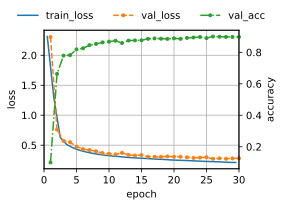

In [4]:
trainer = d2l.Trainer(max_epochs=30, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128)
model = LeNet(lr=2.0)
trainer.fit(model, data)

Even at this learning rate the validation accuracy can stay at chance, 10%,
before it climbs; how long it stays there varies from run to run, from no
epoch at all to several. After 30 epochs LeNet reaches a validation
accuracy of about 88--90%, against about 87% for the MLP, with fewer than a
third of the MLP's parameters. A convolution kernel learns a local pattern
once and detects it at every position, whereas the MLP must learn the
pattern separately for each position at which it occurs.

## Summary

LeNet combines a convolutional encoder, in which the resolution shrinks while
the number of channels grows, with a small fully connected head. Its
convolutional layers hold few parameters and do most of the arithmetic; the
first fully connected layer holds most of the parameters. Trained with the
loss, the optimizer, and the 30 epochs of the MLP of
that section, it reaches about 88--90% validation
accuracy on Fashion-MNIST, against about 87% for the MLP, with fewer than a
third of the MLP's parameters. Its sigmoid activations need a learning rate
twenty times that of the MLP, because each sigmoid shrinks the backward
gradient by a factor of at least four.

The encoder followed by a classifier head remains the organization of most
convolutional networks, although modern networks replace most of LeNet's
components:

<!-- tbl-caption:Component substitutions from LeNet to modern CNNs. -->

| LeNet (this section) | Modern (2020s) | Effect of the change |
|:--|:--|:--|
| sigmoid activation | ReLU or GELU | gradients that survive depth instead of shrinking at every layer |
| average pooling | max-pooling or strided convolution | selective or learned local downsampling |
| no normalization | batch or layer normalization | stable activation scales, so much deeper stacks train |
| dense head on flattened features | global average pooling plus one linear layer | removes most of the parameters (the $400 \times 120$ block here) |
| Xavier initialization | He initialization | variance matched to the ReLU |

The next chapter makes these changes one at a time, starting with AlexNet
(that section), and asks what each one contributes as networks grow
much deeper.

## Exercises

1. [code] **Modern components.** Retrain `LeNet` with the changes below,
   using the training settings of this section, and compare the
   validation accuracy of each variant after 30 epochs with that of
   `LeNet`.
    1. Replace average pooling with max-pooling.
    1. Replace the sigmoid activations with ReLU. If the loss diverges or
       the accuracy stays at chance, lower the learning rate until training
       succeeds, and report the learning rate you used.
    1. Make both changes together, and call the result the modernized
       LeNet. Which of the two changes accounts for most of the difference
       in accuracy?
    1. ● With the weights the model has at the start of training, measure
       for `LeNet` and for the modernized LeNet the norm of the gradient of
       the loss with respect to the first convolutional kernel, and the
       standard deviation of the logits across a minibatch. The derivation
       of Xavier initialization in that section assumes inputs
       with zero mean and no nonlinearity. Use the mean of the sigmoid's
       output and its slope
       $\sigma'(0) = 1/4$ to explain your measurements, the learning
       rate that `LeNet` needs, and the epochs at chance at the start of
       its training.

1. [code] **Original MNIST.** Write an `MNIST` data class by adapting
   `d2l.FashionMNIST`, and train both `LeNet` and the MLP of
   that section on it, with the settings that each
   uses for Fashion-MNIST. @LeCun.Bottou.Bengio.ea.1998 report a
   test error rate below 1% for LeNet-5 on MNIST.
    1. Compare the test error rate of `LeNet` with this figure.
    1. For each dataset, compute the difference and the ratio of the test
       error rates of the two networks. that section states
       that MNIST makes differences among model classes less visible. Does
       each of the two measures support this statement?

1. [code] **Activation maps.** Train the modernized LeNet of
   problem 1 and extract the feature maps of its first and second
   convolutional layers, each taken after its ReLU.
    1. Display them for test images from two different classes, for
       example pullovers and coats.
    1. Measure the maximum activation of each of the two layers on
       Fashion-MNIST test images, on out-of-distribution photos such as a
       cat or a car, and on uniform random noise. Convert each photo to a
       $28 \times 28$ grayscale image, and keep every input in $[0, 1]$,
       the pixel range of `d2l.FashionMNIST`. Do the maxima for photos and
       noise fall inside or clearly outside the range observed on
       Fashion-MNIST test images?

1. [code] **Overfitting sanity check.** Before trusting a full training
   run, check that a network can memorize a small dataset. Fix a subset
   of 50 Fashion-MNIST training images and train on it with all 50
   images in one minibatch, for at most 500 gradient steps.
    1. For both `LeNet` and the modernized LeNet of problem 1,
       record the number of steps until training accuracy exceeds 99%. If
       a network does not get there, diagnose which architectural or
       optimization choice is responsible.
    1. Name one bug that this check would catch and one that it would
       miss, and explain why the check cannot detect the second.

    *Adapted from Stanford CS231n,
    [Assignment 2](https://cs231n.github.io/assignments2024/assignment2/),
    Convolutional Networks notebook.*

1. **Equivariance versus augmentation.** A stride-1 convolution on an
   infinite grid is exactly translation equivariant.
    1. Go through the layers of `LeNet` in order. Name each component that
       breaks exact translation equivariance of the feature maps, and the
       components that prevent the final prediction from being
       translation invariant.
    1. Explain why training `LeNet` on translated copies of its training
       images can improve test accuracy even though its convolutional
       layers share weights across all locations.

    *Adapted from Michael Nielsen,
    [Neural Networks and Deep Learning](http://neuralnetworksanddeeplearning.com/chap6.html),
    Chapter 6.*

1. [code] **The dense head.** ● the table shows that the
   first fully connected layer holds 78% of LeNet's parameters.
    1. Replace the entire dense head, from the flatten through the output
       layer, by global average pooling followed by a single linear layer
       from 16 to 10 units. How many parameters does the network now
       have? Before training, predict whether the validation accuracy
       changes by more than one percentage point relative to `LeNet`; then
       retrain and compare.
    1. Instead connect the flattened 400-dimensional convolutional output
       directly to a ten-way linear output layer. How many parameters does
       this network have? Retrain, and compare the accuracy of the two
       reduced heads with each other and with your prediction. What does
       the comparison say about where LeNet's capacity is used?

    *Adapted from Michael Nielsen,
    [Neural Networks and Deep Learning](http://neuralnetworksanddeeplearning.com/chap6.html),
    Chapter 6.*

[Discussions](https://d2l.discourse.group/t/275)